# Raw Temporal Graphomotor Learning — Task 2 thay thế

Raw chronological samples → Local movement → Stroke/segment → Task → Participant. Notebook chỉ đọc artifacts; không train hoặc tối ưu khi mở. Bảng số đặt trước hình. [Báo cáo tiếng Việt](../results/raw_temporal/REPORT_VI.md).

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
if not (ROOT/'results/raw_temporal').exists(): ROOT=ROOT.parent
OUT=ROOT/'results/raw_temporal';T=OUT/'tables'
pd.set_option('display.max_columns',40)
pd.set_option('display.max_rows',150)
pd.set_option('display.precision',6)
def read(name):return pd.read_csv(T/(name+'.csv'))
for name in ('data_validation','fit_validation','xai_validation'):
    v=json.loads((OUT/(name+'.json')).read_text());assert v['complete'];display(pd.DataFrame([v]))

,complete,protected_files,participants,recordings,raw_samples,exact_sample_coverage,all_cached_channels_match_raw_preprocessing,all_timestamp_and_stroke_alignment_checked,derivative_masks_checked,original_float32_statistics_recomputed,packed_storage_exactly_validated,maximum_storage_error,obsolete_tracked_task2_removed
0,True,706,258,3612,54808751,True,True,True,True,True,True,0.003906,True


,complete,inner_fits,outer_fits,normalization_train_only,selection_inner_only,all_checkpoint_predictions_replayed,baseline_oof_unchanged,all_participant_metrics_checked
0,True,216,96,True,True,True,True,True


,complete,all_segment_rows_raw_aligned,task_and_sampled_segment_predictions_replayed,full_stroke_and_temporal_alignment_checked,ig_artifacts,all_ig_completeness_checked,device,probability_delta_dtype_arithmetic_reproduced,maximum_float32_sigmoid_roundoff,note
0,True,250225,16342,True,32,True,cpu,True,7.470903e-08,Every segment/stroke/time row checked for mapp...


## Kết quả cuối cùng — OOF và fold mean±SD

R1=CNN; R2=TCN; R3=flat Temporal Transformer; R4=Hierarchical. `nested_selected` chọn model trong inner CV; baseline LightGBM là protected reference. Independent n=258, không phải số windows.

In [2]:
d=read('primary_ablation')
display(d[['model','f1_macro','accuracy','auc','balanced_accuracy','sensitivity','specificity']])
display(d[['model','mean_f1_macro','std_f1_macro','mean_accuracy','std_accuracy','mean_auc','std_auc','mean_balanced_accuracy','std_balanced_accuracy','mean_sensitivity','std_sensitivity','mean_specificity','std_specificity']])

,model,f1_macro,accuracy,auc,balanced_accuracy,sensitivity,specificity
0,cnn,0.571172,0.612403,0.599574,0.585649,0.832168,0.339130
1,hierarchical,0.474579,0.550388,0.536820,0.515233,0.839161,0.191304
2,index_time,0.516801,0.538760,0.527638,0.521770,0.678322,0.365217
3,kinematic_lightgbm_reference,0.847163,0.848837,0.906902,0.847461,0.860140,0.834783
4,local_stroke,0.520821,0.558140,0.550198,0.534144,0.755245,0.313043
5,nested_selected,0.598474,0.604651,0.637580,0.598237,0.657343,0.539130
6,no_explicit_time,0.549328,0.554264,0.585649,0.549377,0.594406,0.504348
7,no_position,0.591772,0.612403,0.615263,0.595014,0.755245,0.434783
8,tcn,0.594927,0.600775,0.632837,0.594740,0.650350,0.539130
9,train_majority_reference,0.356608,0.554264,0.500000,0.500000,1.000000,0.000000


,model,mean_f1_macro,std_f1_macro,mean_accuracy,std_accuracy,mean_auc,std_auc,mean_balanced_accuracy,std_balanced_accuracy,mean_sensitivity,std_sensitivity,mean_specificity,std_specificity
0,cnn,0.553443,0.098832,0.612403,0.056328,0.577374,0.112360,0.585512,0.066225,0.832428,0.136618,0.338596,0.205780
1,hierarchical,0.438812,0.081786,0.550388,0.031773,0.581903,0.088216,0.516630,0.028122,0.840278,0.221134,0.192982,0.241571
2,index_time,0.430292,0.131150,0.538760,0.079773,0.539814,0.131632,0.519840,0.079648,0.677838,0.366337,0.361842,0.413397
3,kinematic_lightgbm_reference,0.847047,0.032387,0.848837,0.032056,0.904027,0.031284,0.847276,0.032343,0.859903,0.035308,0.834649,0.040097
4,local_stroke,0.500527,0.102977,0.558140,0.091853,0.554551,0.081284,0.535051,0.087026,0.756944,0.233358,0.313158,0.185447
5,nested_selected,0.586389,0.071179,0.604651,0.065777,0.639070,0.107377,0.599803,0.075437,0.658816,0.164041,0.540789,0.237448
6,no_explicit_time,0.545693,0.056339,0.554264,0.055846,0.579666,0.090725,0.549309,0.054130,0.595109,0.114545,0.503509,0.102147
7,no_position,0.586343,0.046191,0.612403,0.031773,0.600594,0.078126,0.593712,0.039509,0.754529,0.075557,0.432895,0.132353
8,tcn,0.583007,0.075206,0.600775,0.071174,0.639436,0.106802,0.596331,0.080018,0.651872,0.166621,0.540789,0.237448
9,train_majority_reference,0.356588,0.003970,0.554264,0.009494,0.500000,0.000000,0.500000,0.000000,1.000000,0.000000,0.000000,0.000000


## Paired prediction comparison và confusion matrices

Cùng participants, threshold>0,5; không chọn lại bằng outer Test. Khác error cases chưa chứng minh fusion gain.

In [3]:
display(read('paired_comparisons'))
display(read('confusion_matrices'))

,model,corrected,harmed,mean_delta_f1_macro,std_delta_f1_macro,mean_delta_accuracy,std_delta_accuracy,mean_delta_auc,std_delta_auc,mean_delta_balanced_accuracy,std_delta_balanced_accuracy,mean_delta_sensitivity,std_delta_sensitivity,mean_delta_specificity,std_delta_specificity
0,cnn,17,78,-0.293603,0.081401,-0.236434,0.045135,-0.326653,0.087487,-0.261764,0.053243,-0.027476,0.136270,-0.496053,0.182501
1,hierarchical,20,97,-0.408235,0.076163,-0.298450,0.030911,-0.322124,0.086327,-0.330646,0.034596,-0.019626,0.219762,-0.641667,0.253510
2,index_time,17,97,-0.416755,0.128419,-0.310078,0.087840,-0.364213,0.127958,-0.327436,0.088966,-0.182065,0.363080,-0.472807,0.414026
3,kinematic_lightgbm_reference,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,local_stroke,17,92,-0.346520,0.106914,-0.290698,0.106825,-0.349476,0.077967,-0.312225,0.098412,-0.102959,0.249851,-0.521491,0.158161
5,nested_selected,15,78,-0.260658,0.076101,-0.244186,0.073173,-0.264957,0.091427,-0.247473,0.082689,-0.201087,0.181948,-0.293860,0.254824
6,no_explicit_time,14,90,-0.301353,0.057729,-0.294574,0.058217,-0.324361,0.097815,-0.297968,0.056495,-0.264795,0.127036,-0.331140,0.115435
7,no_position,18,79,-0.260704,0.047105,-0.236434,0.034232,-0.303432,0.065140,-0.253564,0.041774,-0.105374,0.059064,-0.401754,0.121927
8,tcn,15,79,-0.264040,0.079306,-0.248062,0.077364,-0.264591,0.090764,-0.250946,0.086429,-0.208031,0.183071,-0.293860,0.254824
9,train_majority_reference,20,96,-0.490458,0.032016,-0.294574,0.031773,-0.404027,0.031284,-0.347276,0.032343,0.140097,0.035308,-0.834649,0.040097


,model,label,prediction,n
0,cnn,0,0,39
1,cnn,0,1,76
2,cnn,1,0,24
3,cnn,1,1,119
4,hierarchical,0,0,22
5,hierarchical,0,1,93
6,hierarchical,1,0,23
7,hierarchical,1,1,120
8,index_time,0,0,42
9,index_time,0,1,73


## Kiểm tra dự đoán một lớp

Ngưỡng cố định0,5. ROC-AUC phản ánh thứ hạng xác suất, có thể khác0,5 ngay cả khi mọi quyết định cùng một lớp. Bảng này chỉ chẩn đoán sau đánh giá, không dùng chọn lại threshold.

In [4]:
display(read('decision_diagnostics').query('seed==42'))

,model,seed,fold,n,predicted_negative,predicted_positive,single_class_predictions,probability_min,probability_max,probability_std,threshold
0,cnn,42,0,43,11,32,False,0.230807,0.606913,0.084303,0.5
1,cnn,42,1,43,19,24,False,0.120217,0.850897,0.180924,0.5
2,cnn,42,2,43,17,26,False,0.260668,0.757252,0.142590,0.5
3,cnn,42,3,43,10,33,False,0.108601,0.909560,0.245478,0.5
4,cnn,42,4,43,2,41,False,0.348044,0.682222,0.062048,0.5
5,cnn,42,5,43,4,39,False,0.402891,0.573921,0.031117,0.5
18,hierarchical,42,0,43,0,43,True,0.512099,0.532477,0.004936,0.5
19,hierarchical,42,1,43,6,37,False,0.160569,0.659687,0.091321,0.5
20,hierarchical,42,2,43,3,40,False,0.326237,0.820636,0.100004,0.5
21,hierarchical,42,3,43,10,33,False,0.190400,0.631929,0.115952,0.5


## Temporal-information và multi-scale ablation

`no_explicit_time` vẫn giữ derived velocity theo Δt; `no_position` vẫn có CNN order và clock-valued sample inputs. `index_time` giữ integrity boundaries. Đọc đủ giới hạn trong báo cáo.

In [5]:
display(read('temporal_multiscale_ablation'))
display(read('temporal_perturbation_summary'))

,model,reference,mean_delta_f1_macro,std_delta_f1_macro,mean_delta_accuracy,std_delta_accuracy,mean_delta_auc,std_delta_auc,mean_delta_balanced_accuracy,std_delta_balanced_accuracy
0,index_time,hierarchical,-0.008520,0.176796,-0.011628,0.078864,-0.042089,0.051628,0.003210,0.088660
1,local_stroke,hierarchical,0.061715,0.105020,0.007752,0.096074,-0.027352,0.041230,0.018421,0.078872
2,no_explicit_time,hierarchical,0.106881,0.115620,0.003876,0.071174,-0.002237,0.042708,0.032679,0.068456
3,no_position,hierarchical,0.147531,0.115844,0.062016,0.037977,0.018691,0.039164,0.077082,0.054453


,kind,f1_macro_mean,f1_macro_std,accuracy_mean,accuracy_std,auc_mean,auc_std,balanced_accuracy_mean,balanced_accuracy_std,sensitivity_mean,sensitivity_std,specificity_mean,specificity_std,delta_f1_macro_mean,delta_f1_macro_std,delta_accuracy_mean,delta_accuracy_std,delta_auc_mean,delta_auc_std,delta_balanced_accuracy_mean,delta_balanced_accuracy_std,delta_sensitivity_mean,delta_sensitivity_std,delta_specificity_mean,delta_specificity_std,mean_absolute_probability_shift_mean,mean_absolute_probability_shift_std
0,missing_segments_0.1,0.439645,0.082627,0.551680,0.032305,0.587114,0.092521,0.518092,0.028879,0.840278,0.225967,0.195906,0.247963,0.000833,0.002500,0.001292,0.003165,0.005211,0.010131,0.001462,0.002784,3.180326e-18,0.008784,0.002924,0.007162,0.006519,0.006131
1,missing_segments_0.25,0.442960,0.090898,0.552972,0.054960,0.569576,0.088464,0.520468,0.043139,0.833333,0.255042,0.207602,0.246219,0.004148,0.031729,0.002584,0.027150,-0.012327,0.042992,0.003838,0.026084,-6.944444e-03,0.038036,0.014620,0.023319,0.015169,0.013557
2,reverse_runs,0.438812,0.081786,0.550388,0.031773,0.581544,0.085904,0.516630,0.028122,0.840278,0.221134,0.192982,0.241571,0.000000,0.000000,0.000000,0.000000,-0.000359,0.003769,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.001598,0.001590
3,shuffle_runs,0.436665,0.075984,0.554264,0.030911,0.578746,0.089115,0.519189,0.022501,0.854167,0.227837,0.184211,0.241762,-0.002147,0.012286,0.003876,0.009494,-0.003157,0.012233,0.002558,0.009217,1.388889e-02,0.021517,-0.008772,0.021487,0.006799,0.007766


## Từng fold, inner choices và seeds

Mean±SD mô tả6 folds, không là confidence intervals. Repeated seeds dùng cùng cohort và configurations, không là independent confirmation.

In [6]:
display(read('fold_results').query('seed==42').sort_values(['model','fold']))
display(read('selected_configurations'))
display(read('seed_sensitivity'))

,model,seed,fold,f1_macro,accuracy,auc,balanced_accuracy,sensitivity,specificity
0,cnn,42,0,0.621701,0.651163,0.576087,0.634783,0.869565,0.400000
1,cnn,42,1,0.669956,0.674419,0.754386,0.669956,0.708333,0.631579
2,cnn,42,2,0.522222,0.534884,0.497807,0.523026,0.625000,0.421053
3,cnn,42,3,0.609800,0.651163,0.660088,0.621711,0.875000,0.368421
4,cnn,42,4,0.401465,0.558140,0.451754,0.505482,0.958333,0.052632
5,cnn,42,5,0.495514,0.604651,0.524123,0.558114,0.958333,0.157895
18,hierarchical,42,0,0.348485,0.534884,0.728261,0.500000,1.000000,0.000000
19,hierarchical,42,1,0.520656,0.604651,0.620614,0.563596,0.916667,0.210526
20,hierarchical,42,2,0.389205,0.534884,0.543860,0.484649,0.916667,0.052632
21,hierarchical,42,3,0.505747,0.558140,0.596491,0.527412,0.791667,0.263158


,fold,model,candidate,epochs,inner_f1,nested_winner
0,0,cnn,1,13,0.446690,tcn
1,0,tcn,1,10,0.472490,tcn
2,0,transformer,1,10,0.458858,tcn
3,0,hierarchical,0,5,0.358215,tcn
4,0,no_explicit_time,0,10,NaN,tcn
5,0,no_position,0,11,NaN,tcn
6,0,index_time,0,7,NaN,tcn
7,0,local_stroke,0,5,NaN,tcn
8,1,cnn,0,18,0.529719,tcn
9,1,tcn,1,16,0.545858,tcn


,model,f1_macro_mean,f1_macro_std,accuracy_mean,accuracy_std,auc_mean,auc_std,balanced_accuracy_mean,balanced_accuracy_std,sensitivity_mean,sensitivity_std,specificity_mean,specificity_std
0,cnn,0.548157,0.028490,0.572351,0.040713,0.598682,0.064948,0.554343,0.033995,0.720280,0.100855,0.388406,0.044623
1,hierarchical,0.501141,0.024493,0.567183,0.029091,0.556664,0.018240,0.535208,0.022663,0.829837,0.112179,0.240580,0.092980
2,nested_selected,0.599784,0.039756,0.617571,0.044079,0.660383,0.065006,0.602513,0.040335,0.741259,0.096138,0.463768,0.067543
3,tcn,0.598227,0.052137,0.622739,0.048463,0.660930,0.065439,0.604621,0.047374,0.771562,0.108636,0.437681,0.109418
4,transformer,0.548383,0.045112,0.593023,0.030765,0.598014,0.049849,0.566180,0.034944,0.813520,0.035885,0.318841,0.083557


## Raw data audit và full coverage

Không sort/drop timestamp anomalies, không resample whole tasks, không dùng engineered74 features. Đơn vị thời gian theo source convention, chưa có calibration certificate.

In [7]:
display(pd.DataFrame([json.loads((OUT/'audit/summary.json').read_text())]))
display(pd.read_csv(OUT/'audit/recordings.csv').groupby('task').agg(n=('n_samples','size'),samples_median=('n_samples','median'),samples_max=('n_samples','max'),duplicates=('duplicate_dt','sum'),large_gaps=('large_dt_over_1s','sum')).reset_index())
display(pd.read_csv(OUT/'audit/window_tradeoff.csv').groupby('patch_size')[['patches','raw_samples','padded_cells']].sum().reset_index())

,participants,recordings,channels,label,class_counts,samples,n_samples_quantiles,duration_quantiles,duplicate_dt,negative_dt,tiny_dt,large_gaps,nonfinite,pen_states,raw_float32_gib,seconds,timestamp_units,policy
0,258,3612,"[x, y, pressure, tilt, azimuth, time, pen_status]",group,"{'0': 115, '1': 143}",54808751,"{'0.0': 127.0, '0.25': 1285.0, '0.5': 2569.0, ...","{'0.0': 0.673, '0.5': 14.5985, '0.95': 556.359...",21283,0,0,20725,0,"[0.0|1.0, 1.0]",1.42925,144.770047,"source numerical time, treated as seconds foll...",Keep every sample in recorded acquisition orde...


,task,n,samples_median,samples_max,duplicates,large_gaps
0,RCFT-recall,258,15574.0,94835,1942,2645
1,RCFT-recognition,258,25627.0,105525,2029,5714
2,big-spiral-fast,258,1277.5,9608,6,38
3,combined-loops-fast,258,2868.0,15641,60,88
4,combined-loops-precise,258,3516.0,8643,29,85
5,copy,258,55697.0,155103,6924,5551
6,dictation,258,82325.5,199739,10160,6322
7,lower-loops-fast,258,1929.5,6144,53,67
8,lower-loops-precise,258,2723.5,6240,27,60
9,rainbow-fast,258,1223.5,4190,8,33


,patch_size,patches,raw_samples,padded_cells
0,64,987790,54808751,8409809
1,128,567707,54808751,17857745
2,256,373336,54808751,40765265


## Overfitting và computational cost

Online Train curve có dropout/weights đang thay đổi; validation chạy eval. Tensor peak không gồm driver/context. Training chạy tuần tự một GPU worker; bảng latency đo warm CPU forward với hai threads, khác thiết bị và scope so với GPU inference cho toàn fold.

In [8]:
display(read('overfitting').groupby('model')[['best_epoch','loss_gap','max_epochs_reached']].mean().reset_index())
display(read('primary_ablation')[['model','parameters','parameters_max','train_seconds_mean','inference_seconds_mean','peak_gpu_bytes']])
display(read('latency').groupby('model').seconds.agg(['median','mean','std']).reset_index())

,model,best_epoch,loss_gap,max_epochs_reached
0,cnn,10.694444,0.000169,0.277778
1,hierarchical,9.138889,-0.008361,0.250000
2,index_time,8.000000,-0.013823,0.166667
3,local_stroke,5.500000,-0.013187,0.055556
4,no_explicit_time,5.666667,-0.009326,0.000000
5,no_position,6.888889,-0.004319,0.055556
6,tcn,9.833333,0.004122,0.222222
7,transformer,8.583333,-0.009510,0.111111


,model,parameters,parameters_max,train_seconds_mean,inference_seconds_mean,peak_gpu_bytes
0,cnn,4178.0,4178.0,34.922011,0.869048,1.054911e+09
1,hierarchical,29810.0,29810.0,58.270288,0.554199,1.099787e+09
2,index_time,29810.0,29810.0,70.897624,1.887803,1.115845e+09
3,kinematic_lightgbm_reference,NaN,NaN,NaN,NaN,NaN
4,local_stroke,12722.0,12722.0,28.855574,1.113521,1.099705e+09
5,nested_selected,NaN,NaN,NaN,NaN,NaN
6,no_explicit_time,29810.0,29810.0,30.246492,0.558986,1.113806e+09
7,no_position,29810.0,29810.0,36.954449,0.555697,1.113806e+09
8,tcn,13554.0,13554.0,35.575672,0.449493,1.055029e+09
9,train_majority_reference,NaN,NaN,NaN,NaN,NaN


,model,median,mean,std
0,cnn,0.039941,0.043863,0.016386
1,hierarchical,0.063314,0.068540,0.026765
2,tcn,0.046452,0.054173,0.028546
3,transformer,0.042147,0.044895,0.017009


In [9]:
display(read('computational_cost_by_scope'))

,model,scope,n_fits,train_seconds_sum,train_seconds_mean,evaluation_seconds_sum,peak_tensor_bytes
0,cnn,inner_search,36,1438.271335,39.951982,29.883289,1041853440
1,cnn,outer_train,18,629.786642,34.988147,10.302215,1054910976
2,hierarchical,inner_search,36,2030.141325,56.392815,33.345210,1180416512
3,hierarchical,outer_train,18,1046.983902,58.165772,10.075050,1099786752
4,index_time,inner_search,18,2176.164793,120.898044,50.871182,1180416512
5,index_time,outer_train,6,425.385744,70.897624,11.326818,1115844608
6,local_stroke,inner_search,18,710.425694,39.468094,15.682788,1180195328
7,local_stroke,outer_train,6,173.133446,28.855574,6.681124,1099704832
8,no_explicit_time,inner_search,18,779.864366,43.325798,16.963163,1178261504
9,no_explicit_time,outer_train,6,181.478951,30.246492,3.353916,1113806336


## Task importance cho toàn bộ held-out participants

Occlusion reliance là thay đổi output, không phải Shapley value hoặc clinical relevance. Kinematic SHAP chỉ đối chiếu mô tả, không dùng làm neural weights.

In [10]:
display(read('task_importance').query('seed==42').sort_values(['model','rank']))
display(read('kinematic_xai_rank_comparison'))
display(read('task_faithfulness'))

,model,seed,task,mean_absolute_logit_delta,mean_signed_logit_delta,mean_absolute_probability_delta,rank
5,cnn,42,copy,0.262775,0.260180,0.057904,1.0
6,cnn,42,dictation,0.243836,0.232991,0.050772,2.0
7,cnn,42,lower-loops-fast,0.205927,-0.107279,0.043960,3.0
8,cnn,42,lower-loops-precise,0.143513,-0.141158,0.031903,4.0
0,cnn,42,RCFT-recall,0.143461,-0.143461,0.030959,5.0
11,cnn,42,small-spiral-fast,0.090930,-0.009707,0.019409,6.0
4,cnn,42,combined-loops-precise,0.088548,-0.083816,0.018547,7.0
2,cnn,42,big-spiral-fast,0.088333,0.058716,0.019582,8.0
3,cnn,42,combined-loops-fast,0.083042,-0.074759,0.018409,9.0
10,cnn,42,saw-fast,0.082608,0.081132,0.018329,10.0


,model,reference,spearman
0,cnn,"Kinematic TreeSHAP, descriptive only; differen...",0.679121
1,tcn,"Kinematic TreeSHAP, descriptive only; differen...",0.613187
2,transformer,"Kinematic TreeSHAP, descriptive only; differen...",-0.085714
3,hierarchical,"Kinematic TreeSHAP, descriptive only; differen...",0.538462


,model,comparison,spearman
0,cnn,mean_absolute_logit_delta_vs_task_macroF1_drop,0.393407
1,tcn,mean_absolute_logit_delta_vs_task_macroF1_drop,0.011001
2,transformer,mean_absolute_logit_delta_vs_task_macroF1_drop,-0.296703
3,hierarchical,mean_absolute_logit_delta_vs_task_macroF1_drop,0.050549


## Stroke và temporal intervals

Mapping về original pen-state run, down-stroke index, raw indices và timestamps. Bao gồm cả pen-up segments; không ghép thành trajectory liên tục giả.

In [11]:
display(read('behavioral_examples'))

,participant_id,category,task,window_index,raw_start,raw_end_exclusive,samples,pen_state,time_start,time_last,elapsed_start,elapsed_last,duration,valid_speed_samples,speed_median,speed_max,valid_acceleration_samples,acceleration_median,acceleration_max,pressure_min,pressure_median,pressure_max,boundaries,invalid_time_samples,source_file,source_sha256,selection
0,BR10301,FP,combined-loops-precise,12,1536,1664,128,1,8.199,8.877,8.199,8.877,0.678,128,164.176684,205.231577,128,4460.714665,7653.902418,4543.388653,4951.401105,4989.402264,0,0,data/raw_data/handwriting_data/data_SVC/BR1030...,8ad62a5e34e64f92dbb25eab4c777cd456e6d586aa34c5...,Task: max absolute occlusion effect; window: m...
1,BR10306,TP,copy,142,15627,15687,60,1,96.555,96.868,96.555,96.868,0.313,59,50.000000,227.068272,58,2096.836864,18798.804795,773.023591,3296.850612,4041.373333,1,0,data/raw_data/handwriting_data/data_SVC/BR1030...,3ec34fe7a5c21952751254a13fe4cb013c47367e90f0fc...,Task: max absolute occlusion effect; window: m...
2,BR2406,TN,lower-loops-fast,4,423,551,128,0,2.258,2.936,2.258,2.936,0.678,0,NaN,NaN,0,NaN,NaN,0.000000,0.000000,0.000000,1,0,data/raw_data/handwriting_data/data_SVC/BR2406...,0be43f535f62a9242951d9b11da51e25707f23f32f0923...,Task: max absolute occlusion effect; window: m...
3,HK03402,FN,small-spiral-fast,19,2161,2205,44,1,13.260,13.489,13.260,13.489,0.229,43,30.184617,117.200683,42,788.888889,10542.822730,815.024873,2585.078890,3762.364818,1,0,data/raw_data/handwriting_data/data_SVC/HK0340...,fdeab2afc28ae42ec120c4bd6f7701354c6b6ef102763c...,Task: max absolute occlusion effect; window: m...


In [12]:
s=read('stroke_occlusion');display(s.assign(absolute_effect=s.logit_delta.abs()).sort_values('absolute_effect',ascending=False).head(30))
s=read('temporal_occlusion');display(s.assign(absolute_effect=s.logit_delta.abs()).sort_values('absolute_effect',ascending=False).head(30))

,participant_id,fold,segment_index,task_index,task,original_run_index,stroke_index,pen_state,raw_start,raw_end_exclusive,time_start,time_last,segments,logit,removed_logit,logit_delta,probability_delta,absolute_effect
187663,SO01404,4,739,9,combined-loops-fast,1,-1,0,511,561,2.727,2.989,1,-0.834004,-1.283896,0.449892,0.085911,0.449892
186615,SO01401,4,848,3,big-spiral-fast,1,-1,0,109,168,0.582,0.892,1,-0.834361,-1.235585,0.401224,0.077518,0.401224
184223,RK03402,4,711,7,lower-loops-fast,1,-1,0,775,1139,4.137,6.075,1,-0.933978,-1.324251,0.390272,0.072006,0.390272
188695,TL10404,4,801,5,saw-fast,1,-1,0,631,675,3.368,7.382,2,0.040821,-0.336365,0.377186,0.093511,0.377186
186620,SO01401,4,853,6,upper-loops-fast,1,-1,0,527,599,2.813,3.440,1,-0.834361,-1.207344,0.372983,0.072553,0.372983
190931,TU03405,4,727,11,lower-loops-precise,1,-1,0,94,312,0.502,4.482,2,0.294020,-0.072440,0.366460,0.091082,0.366460
153139,BR3307,4,379,7,lower-loops-fast,1,-1,0,1055,1133,5.631,7.828,2,-0.865689,-1.212244,0.346555,0.066848,0.346555
170575,HK05401,4,544,9,combined-loops-fast,1,-1,0,362,407,1.932,2.167,1,-0.432362,-0.774245,0.341883,0.078001,0.341883
158696,BR5415,4,788,12,combined-loops-precise,1,-1,0,4623,4754,24.677,41.788,3,-0.422599,-0.763516,0.340917,0.078012,0.340917
189810,TU03404,4,820,8,rainbow-fast,1,-1,0,517,574,2.760,8.270,2,0.194647,-0.141758,0.336405,0.083889,0.336405


,participant_id,fold,task,task_index,block,patch_start,patch_end_exclusive,raw_start,raw_end_exclusive,time_start,time_last,logit,removed_logit,logit_delta,probability_delta,absolute_effect
22950,SO01404,4,combined-loops-fast,9,1,1538,1541,384,689,2.049,3.668,-0.834004,-1.300836,0.466833,0.088775,0.466833
19025,BR3307,4,small-spiral-fast,4,7,848,849,896,939,4.783,5.007,-0.865689,-0.446456,-0.419233,-0.094052,0.419233
22827,SO01401,4,upper-loops-fast,6,5,1718,1719,527,599,2.813,3.440,-0.834361,-1.207344,0.372983,0.072553,0.372983
23036,TL10404,4,upper-loops-fast,6,0,1776,1778,0,23,0.000,0.118,0.040821,-0.331460,0.372281,0.092319,0.372281
23288,TU03405,4,lower-loops-precise,11,0,1427,1430,0,243,0.000,4.114,0.294020,-0.069563,0.363583,0.090364,0.363583
22851,SO01401,4,small-spiral-precise,10,0,1753,1758,0,544,0.000,2.893,-0.834361,-1.188168,0.353807,0.069137,0.353807
19043,BR3307,4,lower-loops-fast,7,3,874,876,1055,1133,5.631,7.828,-0.865689,-1.212243,0.346555,0.066848,0.346555
22799,SO01401,4,big-spiral-fast,3,0,1674,1677,0,296,0.000,1.568,-0.834361,-1.178536,0.344175,0.067408,0.344175
21100,HK05401,4,combined-loops-fast,9,1,1161,1163,256,407,1.367,2.167,-0.432362,-0.775970,0.343608,0.078373,0.343608
19717,BR5415,4,combined-loops-precise,12,6,1998,2003,4480,4754,23.914,41.788,-0.422599,-0.762549,0.339950,0.077802,0.339950


## Stability của explanations và representation geometry

Pairwise distances903/fold là các đại lượng phụ thuộc, không phải903 independent subjects. Không so sánh trực tiếp tọa độ latent giữa seeds/folds.

In [13]:
display(read('fold_xai_stability').groupby('model')[['spearman','top3_jaccard']].agg(['mean','std']).reset_index())
display(read('seed_xai_stability').groupby('model').spearman.agg(['mean','std']).reset_index())
display(read('representation_geometry_stability'))

model  spearman           top3_jaccard          
                     mean       std         mean       std
0           cnn  0.380513  0.301748     0.306667  0.349421
1  hierarchical -0.043810  0.286630     0.166667  0.129099
2           tcn  0.614359  0.155057     0.520000  0.280815
3   transformer  0.364982  0.206673     0.280000  0.200713

,model,mean,std
0,cnn,0.087239,0.278685
1,hierarchical,0.182801,0.292980
2,tcn,0.246827,0.287251
3,transformer,0.098390,0.270426


,model,fold,seed,participants,pairwise_distances,spearman,note
0,cnn,0,43,43,903,0.775372,Rotation/translation invariant distance rank c...
1,cnn,0,44,43,903,0.848137,Rotation/translation invariant distance rank c...
2,cnn,1,43,43,903,0.753268,Rotation/translation invariant distance rank c...
3,cnn,1,44,43,903,0.360539,Rotation/translation invariant distance rank c...
4,cnn,2,43,43,903,0.323821,Rotation/translation invariant distance rank c...
5,cnn,2,44,43,903,0.716489,Rotation/translation invariant distance rank c...
6,cnn,3,43,43,903,0.556061,Rotation/translation invariant distance rank c...
7,cnn,3,44,43,903,0.666213,Rotation/translation invariant distance rank c...
8,cnn,4,43,43,903,0.821456,Rotation/translation invariant distance rank c...
9,cnn,4,44,43,903,0.865249,Rotation/translation invariant distance rank c...


## IG completeness, baselines, faithfulness và model randomization

IG giải thích positive-class logit và dùng hai mathematical references. Completeness không chứng minh biological validity. Attention chỉ supplementary.

In [14]:
display(read('ig_validation'))
display(read('faithfulness'))
display(read('ig_baseline_seed_randomization'))
display(read('deletion_curves'))

,participant_id,category,fold,seed,baseline,kind,residual,steps,logit,reference
0,BR10301,FP,4,42,zero_joint,trained,5.075061e-03,16,0.354416,1.499826
1,BR10301,FP,4,42,structure_preserving,trained,-9.797023e-05,64,0.354416,0.206170
2,BR10301,FP,4,9042,zero_joint,random_head,6.198588e-04,32,-0.560878,-0.679940
3,BR10301,FP,4,9042,zero_joint,random_all,2.963510e-08,16,0.273659,0.230154
4,BR10301,FP,4,43,zero_joint,trained,-6.880438e-05,32,-0.099589,1.146108
5,BR10301,FP,4,43,structure_preserving,trained,-2.627218e-04,128,-0.099589,-0.223570
6,BR10301,FP,4,44,zero_joint,trained,-2.263358e-05,16,0.523400,0.735872
7,BR10301,FP,4,44,structure_preserving,trained,-2.748615e-04,32,0.523400,0.471484
8,BR10306,TP,5,42,zero_joint,trained,2.622173e-08,16,0.036088,0.227006
9,BR10306,TP,5,42,structure_preserving,trained,5.404080e-08,16,0.036088,0.029299


,participant_id,baseline,temporal_spearman,task_spearman
0,BR10301,zero_joint,0.580166,0.424176
1,BR10301,structure_preserving,0.710287,-0.340659
2,BR10306,zero_joint,0.086853,-0.380220
3,BR10306,structure_preserving,0.258610,0.551648
4,BR2406,zero_joint,0.561611,-0.498901
5,BR2406,structure_preserving,0.623326,0.090110
6,HK03402,zero_joint,0.533733,-0.692308
7,HK03402,structure_preserving,0.732924,-0.600000


,participant_id,comparison,task_spearman,patch_spearman
0,BR10301,seed_43,0.810989,0.462527
1,BR10301,seed_44,0.934066,0.601447
2,BR10301,structure_preserving,0.349451,0.664231
3,BR10301,random_head,0.819780,0.794976
4,BR10301,random_all,0.081319,0.613226
5,BR10306,seed_43,0.498901,0.974811
6,BR10306,seed_44,0.481319,0.976159
7,BR10306,structure_preserving,0.046154,0.987765
8,BR10306,random_head,0.424176,0.986545
9,BR10306,random_all,0.006593,0.975209


,participant_id,baseline,fraction,kind,confidence_logit_drop,probability
0,BR10301,zero_joint,0.10,IG_top,2.263696,0.129062
1,BR10301,zero_joint,0.10,IG_bottom,0.003124,0.586931
2,BR10301,zero_joint,0.25,IG_top,2.467643,0.107818
3,BR10301,zero_joint,0.25,IG_bottom,0.004079,0.586699
4,BR10301,structure_preserving,0.10,IG_top,1.875518,0.179299
5,BR10301,structure_preserving,0.10,IG_bottom,0.000667,0.587526
6,BR10301,structure_preserving,0.25,IG_top,2.335416,0.121212
7,BR10301,structure_preserving,0.25,IG_bottom,0.003915,0.586739
8,BR10306,zero_joint,0.10,IG_top,-0.061385,0.524349
9,BR10306,zero_joint,0.10,IG_bottom,-0.000037,0.509030


## Ca TP/TN/FP/FN theo quy tắc cố định

ID nhỏ nhất theo từ điển cho mỗi outcome của hierarchical seed42 OOF. Không tạo ca cho category vắng mặt, không đổi threshold hoặc chọn ca đẹp.

In [15]:
display(read('selected_cases'))
display(read('oof_predictions').groupby(['model','seed']).agg(n=('participant_id','size'),unique_ids=('participant_id','nunique')).reset_index())

,participant_id,label,fold,model,seed,probability,prediction,category,selection
0,BR10301,0,4,hierarchical,42,0.587688,1,FP,lexicographically first ID per seed42 hierarch...
1,BR10306,1,5,hierarchical,42,0.509021,1,TP,lexicographically first ID per seed42 hierarch...
2,BR2406,0,4,hierarchical,42,0.156287,0,TN,lexicographically first ID per seed42 hierarch...
3,HK03402,1,4,hierarchical,42,0.188805,0,FN,lexicographically first ID per seed42 hierarch...


,model,seed,n,unique_ids
0,cnn,42,258,258
1,cnn,43,258,258
2,cnn,44,258,258
3,hierarchical,42,258,258
4,hierarchical,43,258,258
5,hierarchical,44,258,258
6,index_time,42,258,258
7,kinematic_lightgbm_reference,42,258,258
8,local_stroke,42,258,258
9,nested_selected,42,258,258


## Hình từ actual recordings và artifact tables

PNG300dpi/SVG paper drafts. Không suy tremor, dysgraphia hoặc nhân quả từ attribution spikes.

**01_raw_data_lengths** — All raw values remain in CSV; boxplots suppress outlier markers only. Time uses source seconds convention.

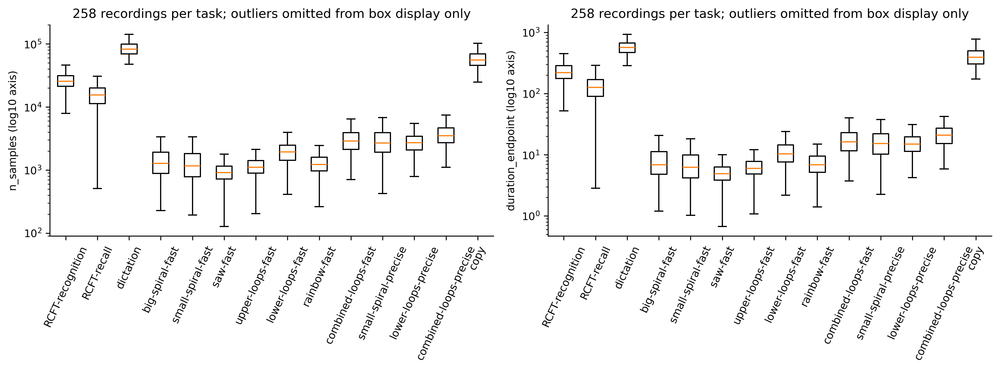

**02_timestamp_and_window_audit** — Fixed safety thresholds and computational window trade-off; no label-based window selection.

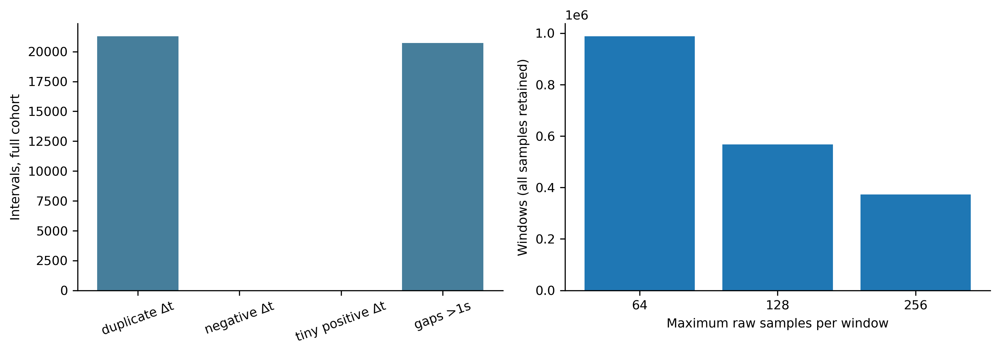

**03_raw_temporal_architecture** — Actual bounded hierarchy; CNN/TCN/flat Transformer are separate raw baselines, no handcrafted74-dimensional input.

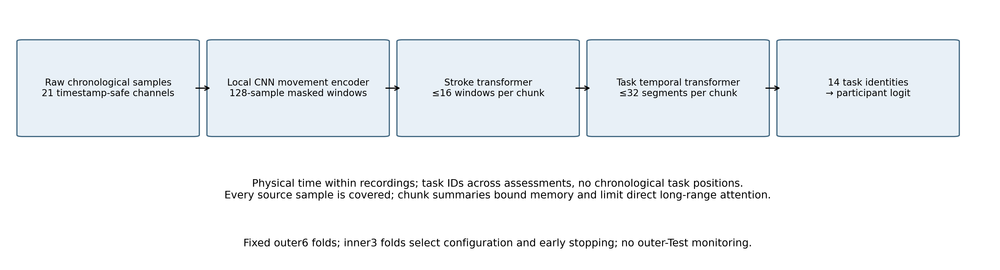

**04_predictive_comparison** — Same258 participants/folds; reference LightGBM unchanged; nested_selected uses Train-only architecture choice.

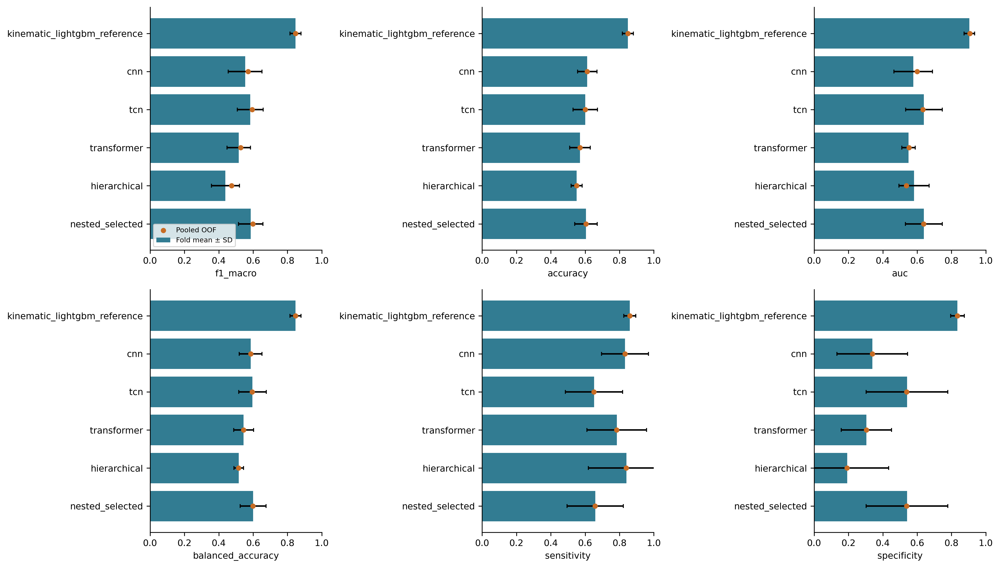

**05_time_and_multiscale_ablation** — Matched hierarchical dropout, Train-only epochs; no_position retains CNN order and clock-valued sample inputs; index_time retains integrity boundaries.

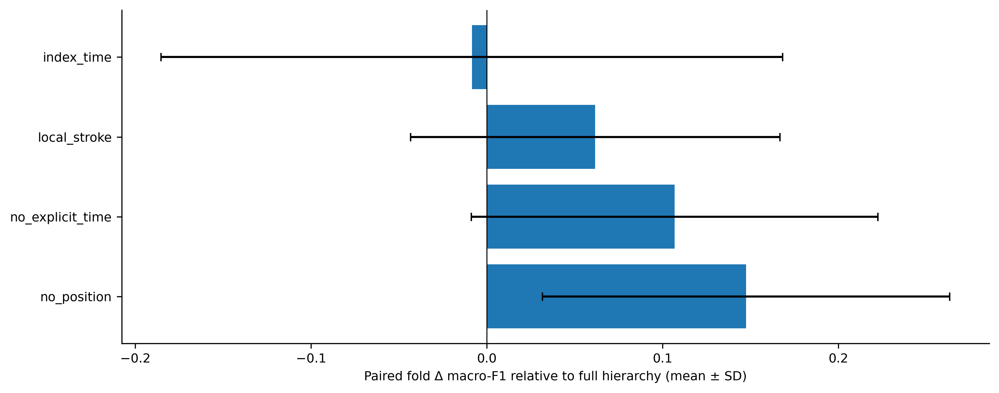

**06_roc_and_seed_sensitivity** — Pooled OOF ROC and seed sensitivity, not external validation or independent cohorts.

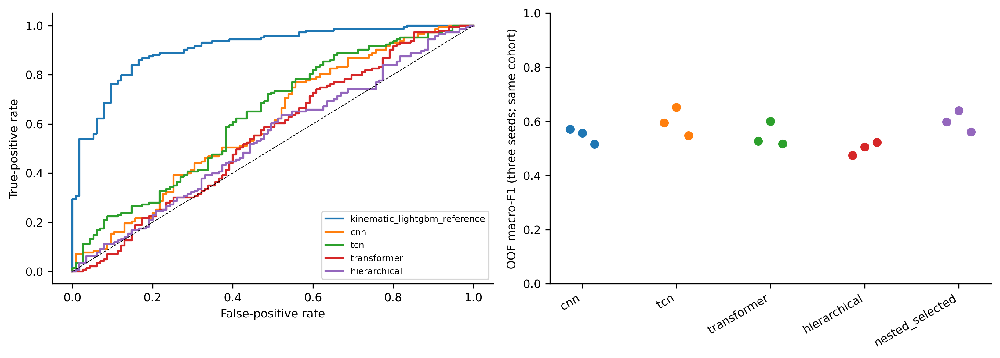

**07_learning_curves** — Online Train uses dropout/changing weights; validation uses eval. Late epochs contain fewer surviving runs due to early stopping.

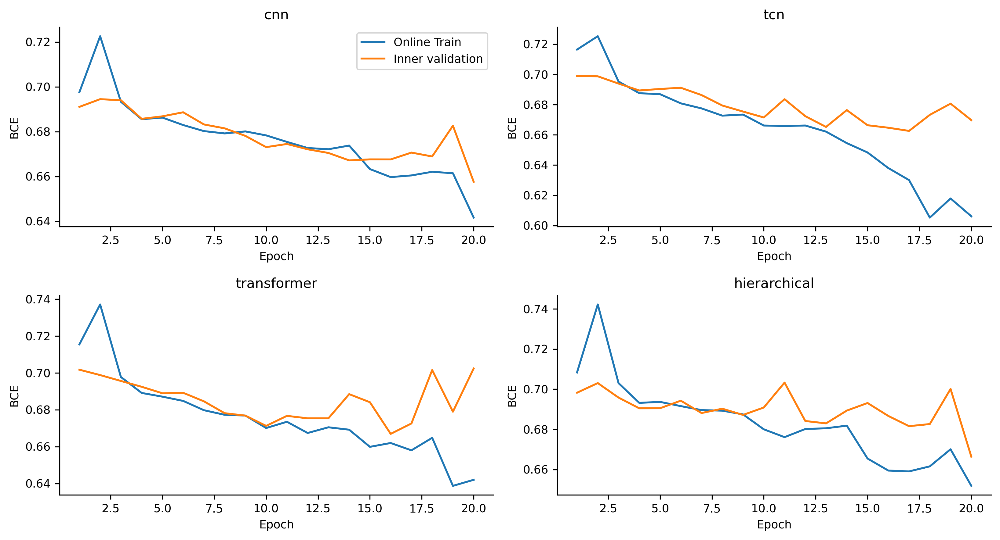

**08_resource_cost** — Final benchmark uses one sequential GPU worker; CPU XAI can share host resources. Descriptive workflow timings, not dedicated hardware benchmarking. Tensor peak excludes CUDA driver/context/reserved memory. All inputs covered, no crops.

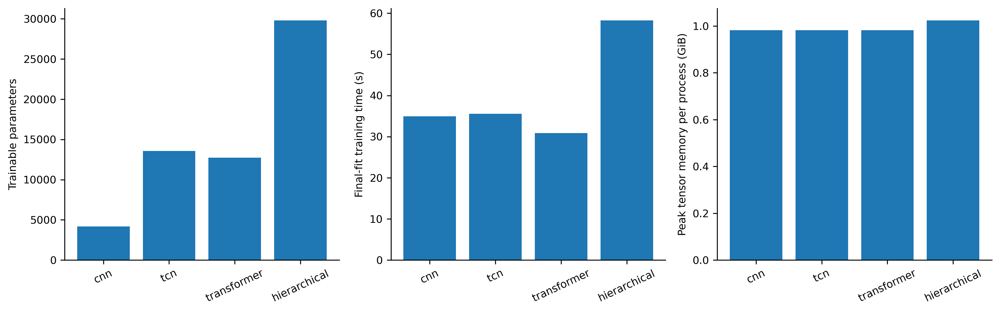

**09_task_importance** — Model reliance measured by missing task tokens; no task selection or neural training weights from Kinematic SHAP.

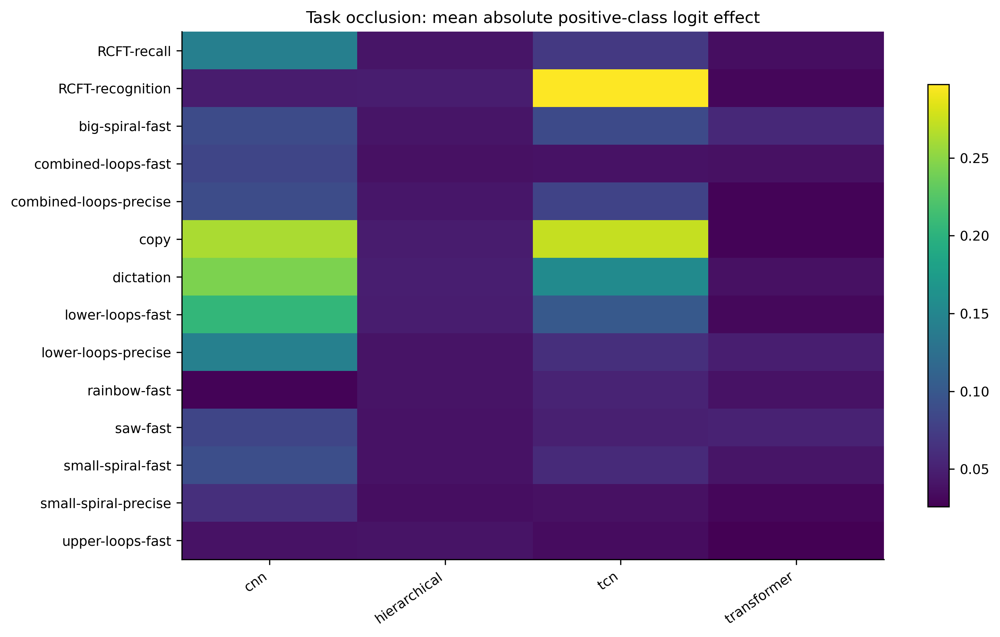

**10_explanation_and_geometry_stability** — Distance-rank geometry is rotation/translation invariant; pairwise distances and fold pairs are dependent.

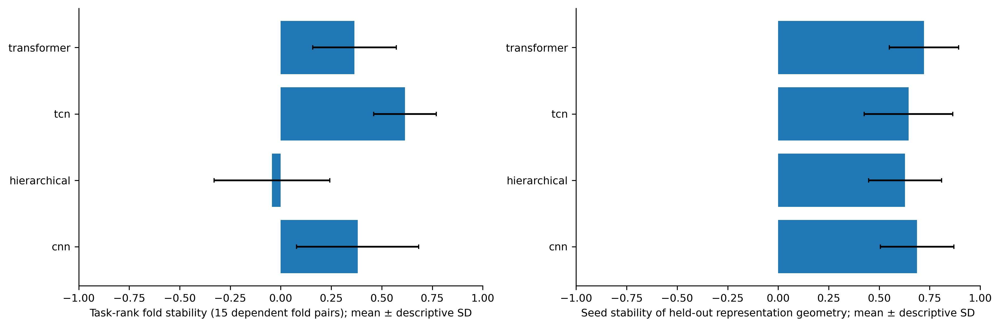

**11_order_and_missing_segments** — Complete pen-state runs reordered; internal movement retained but global timing can be OOD. Missing segments use masks, not artificial zero movement.

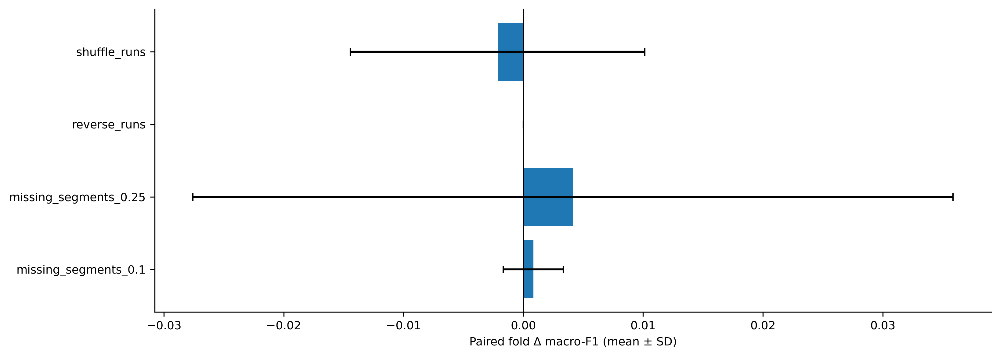

**12_ig_faithfulness_and_sanity** — Documented TP/TN/FP/FN example set only; randomization/baseline sensitivity are diagnostics, not clinical validation.

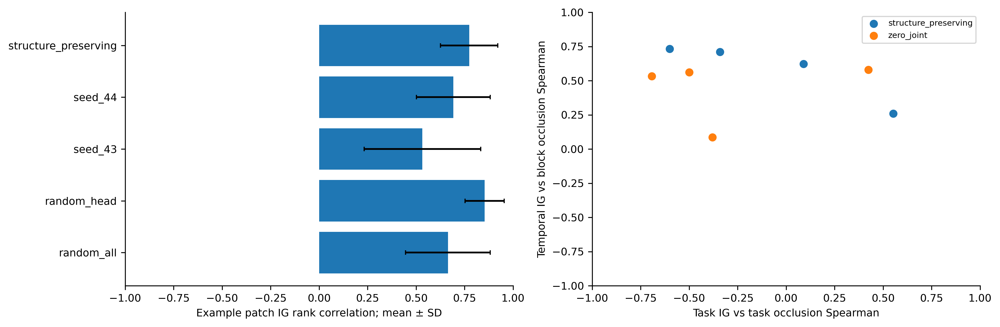

**13_attention_supplementary** — Mean task attention, not automatically a faithful explanation.

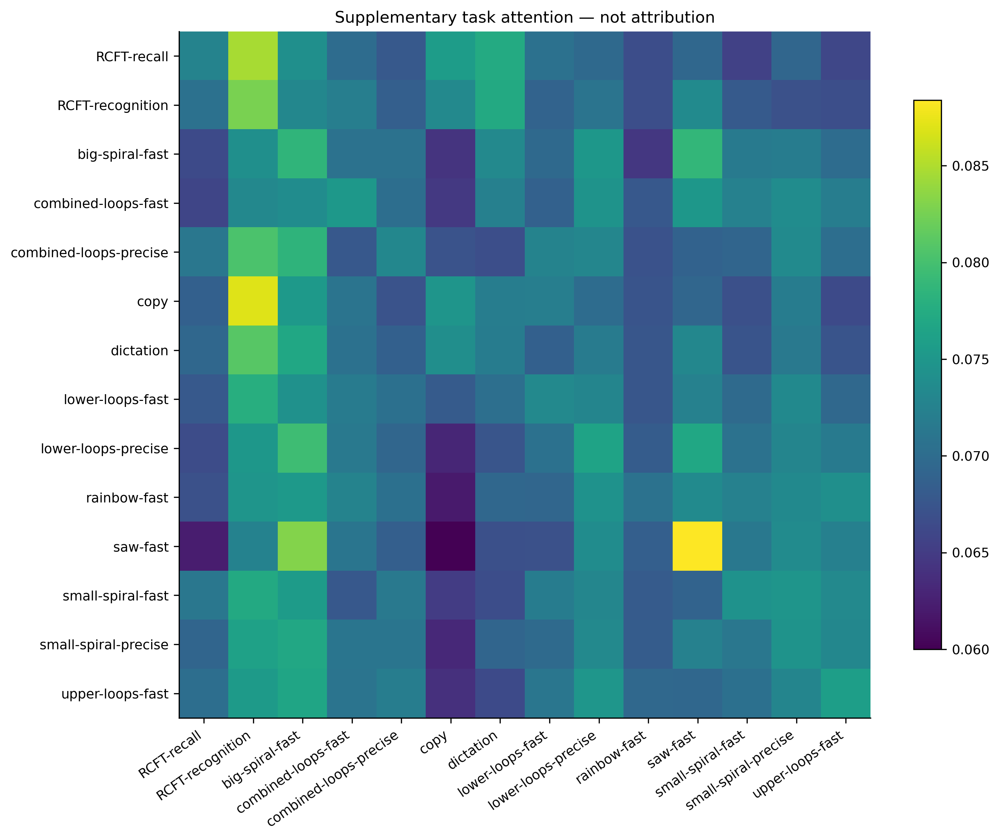

**14_paired_corrected_harmed** — Different error cases are descriptive complementarity hypotheses, not evidence from a trained fusion.

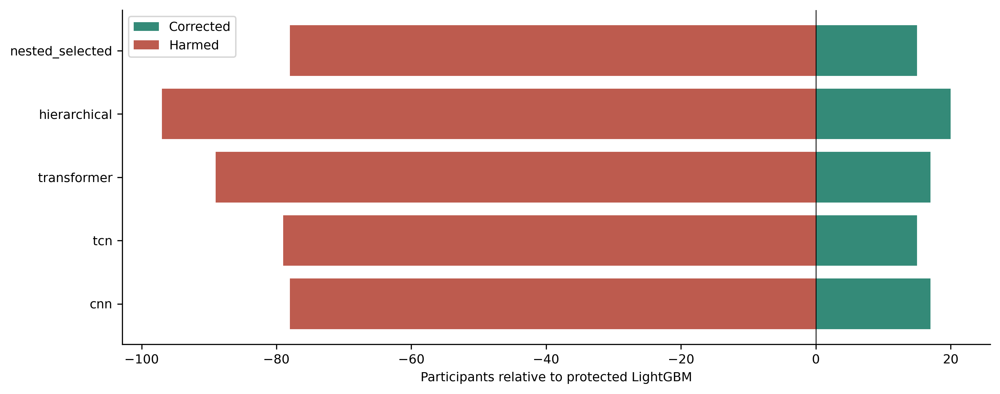

**15_confusion_matrices** — Seed42 participant-level OOF counts; original threshold0.5.

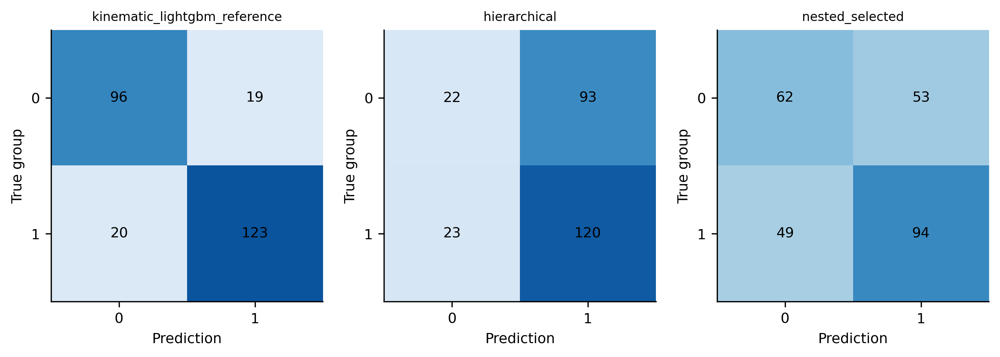

**case_FP_raw_signals** — Actual full source signals, no resampling; rasterized dense traces inside vector SVG. Invalid derivatives are gaps; pen state/boundaries retained. IG overlay includes sample-channel contributions only, time-metadata attribution remains separately stored. No clinical diagnosis inferred.

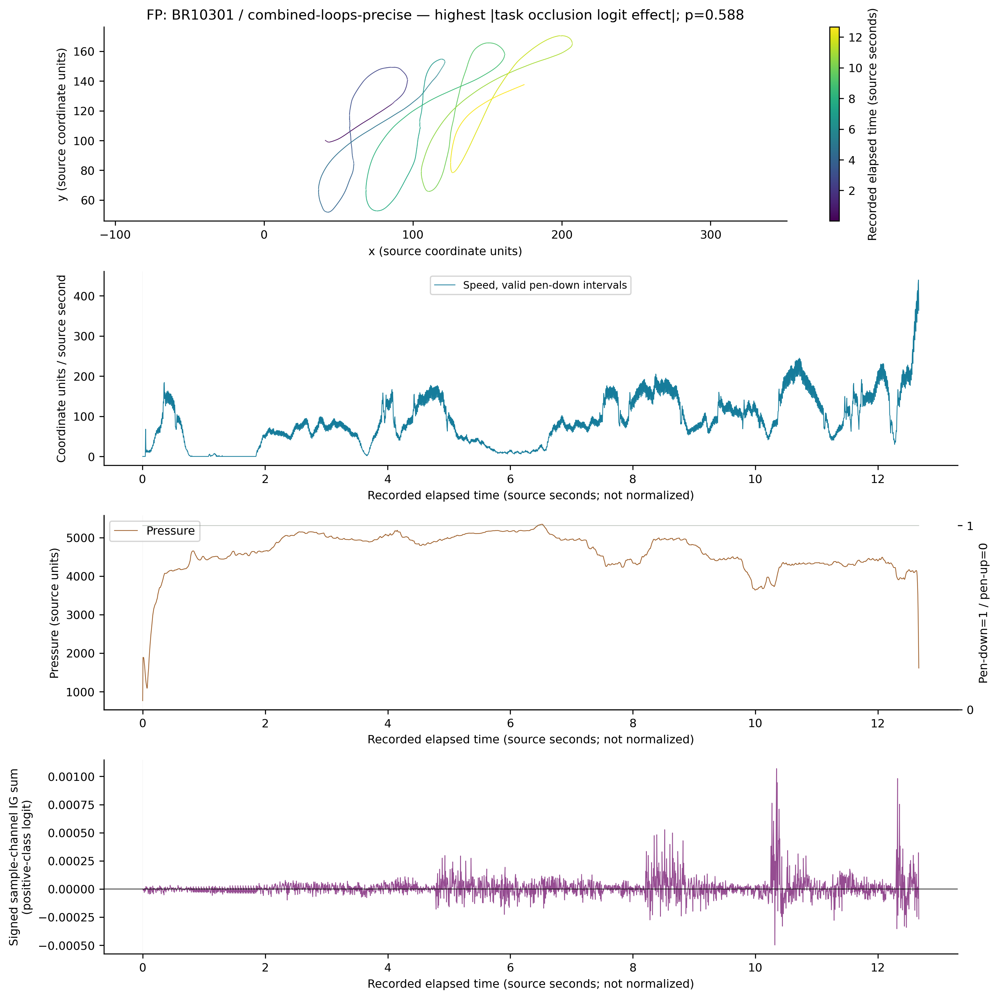

**case_FP_stroke_effects** — Joint whole-run occlusion mapped to original run indices; pen-down/pen-up distinguished; acceleration is a recorded-signal calculation, not a diagnosis.

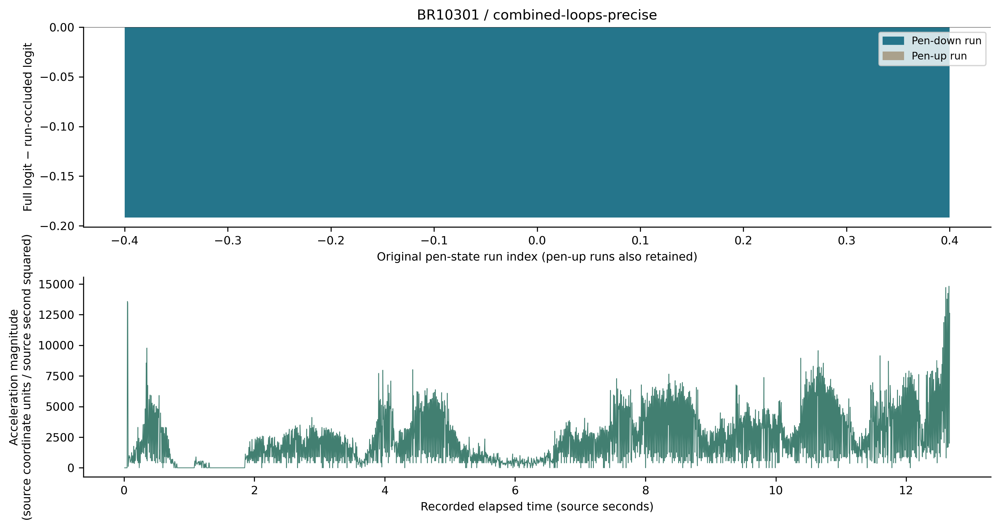

**case_FP_temporal_zoom** — Deterministic highest-absolute-IG window within the displayed task, independently matched to the descriptive table; not selected for visual appearance. No interpolation across invalid/gap intervals; red markers indicate clock boundaries. Narrow events are not diagnosed as tremor or disease.

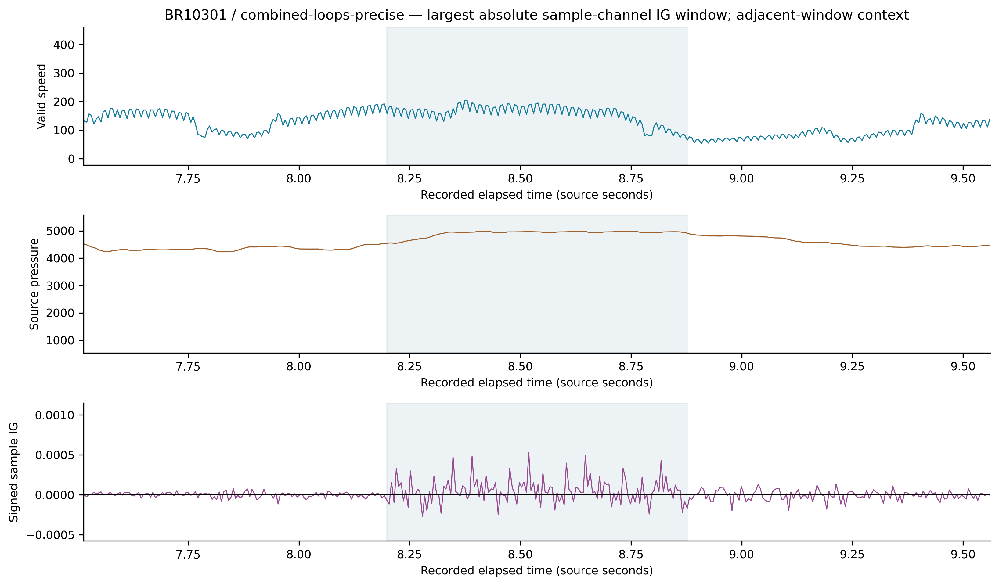

**case_FP_ig_components** — Reference plus signed sample/time-metadata IG approximates actual positive-class logit within validated tolerance. Structural task IDs, masks and segmentation held fixed; reference is mathematical, not a healthy recording.

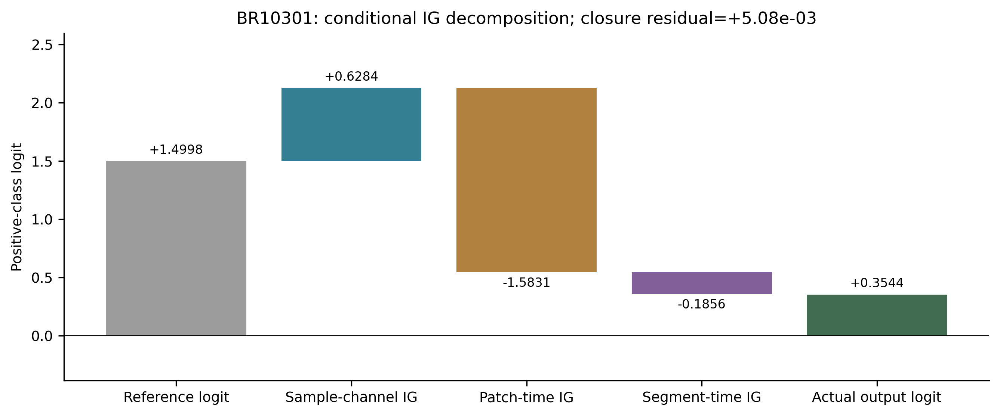

**case_TP_raw_signals** — Actual full source signals, no resampling; rasterized dense traces inside vector SVG. Invalid derivatives are gaps; pen state/boundaries retained. IG overlay includes sample-channel contributions only, time-metadata attribution remains separately stored. No clinical diagnosis inferred.

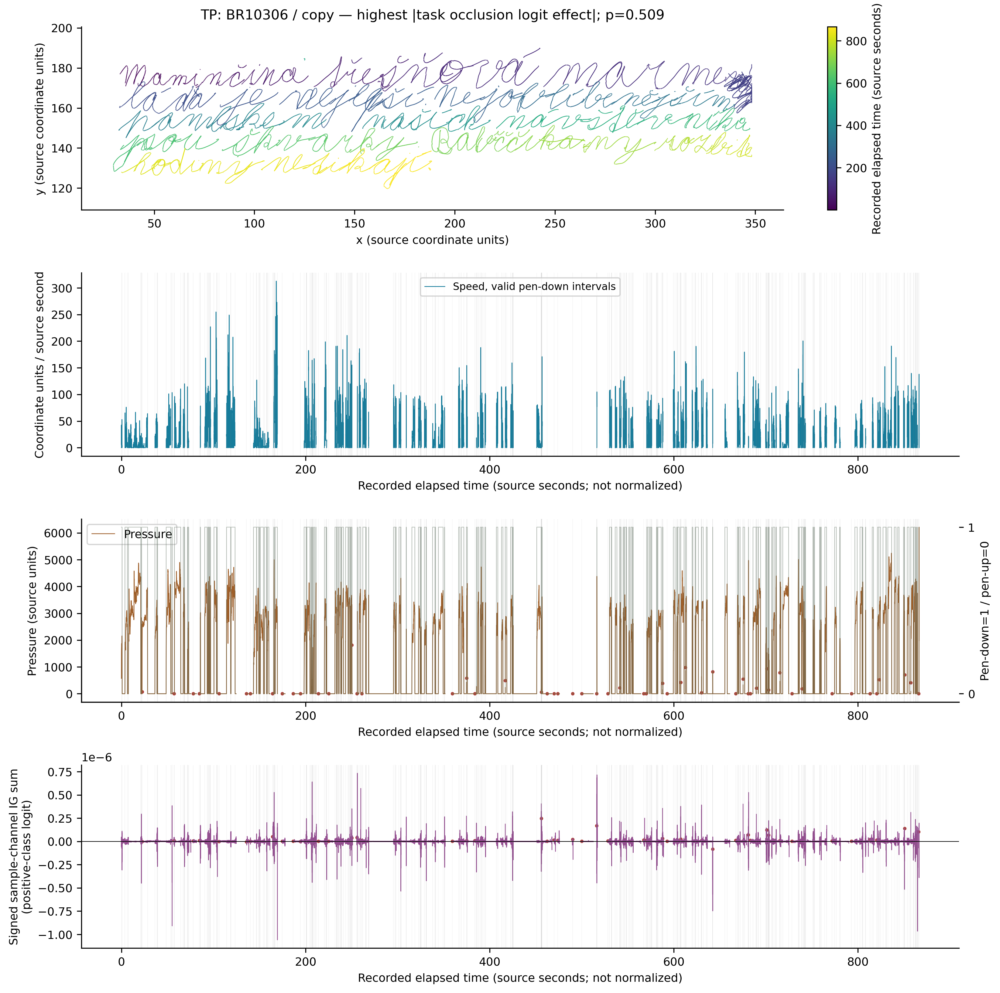

**case_TP_stroke_effects** — Joint whole-run occlusion mapped to original run indices; pen-down/pen-up distinguished; acceleration is a recorded-signal calculation, not a diagnosis.

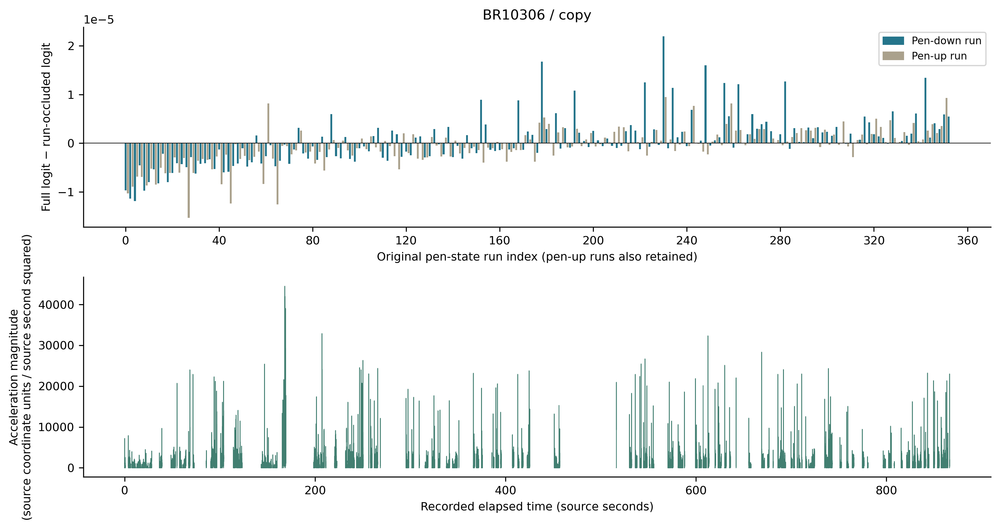

**case_TP_temporal_zoom** — Deterministic highest-absolute-IG window within the displayed task, independently matched to the descriptive table; not selected for visual appearance. No interpolation across invalid/gap intervals; red markers indicate clock boundaries. Narrow events are not diagnosed as tremor or disease.

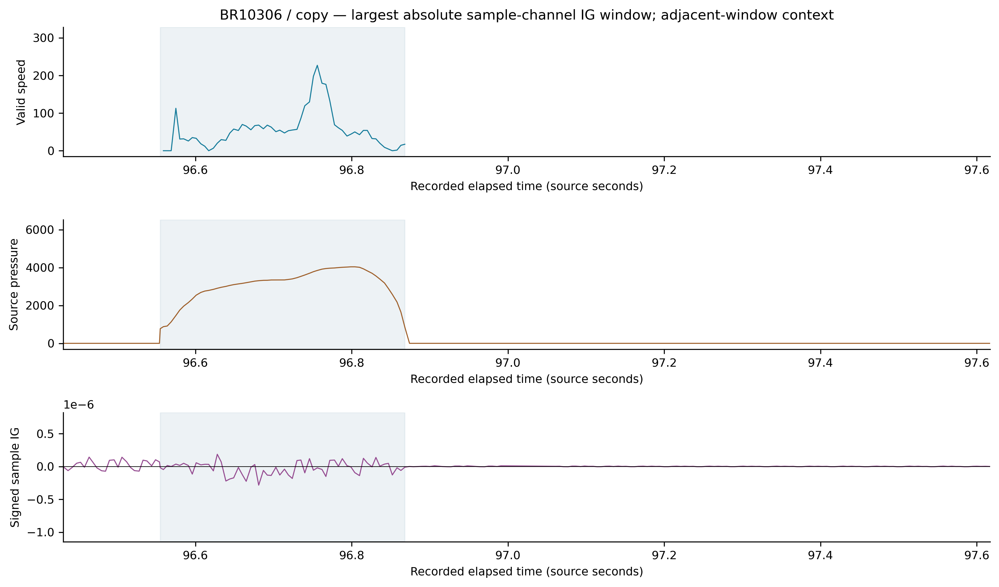

**case_TP_ig_components** — Reference plus signed sample/time-metadata IG approximates actual positive-class logit within validated tolerance. Structural task IDs, masks and segmentation held fixed; reference is mathematical, not a healthy recording.

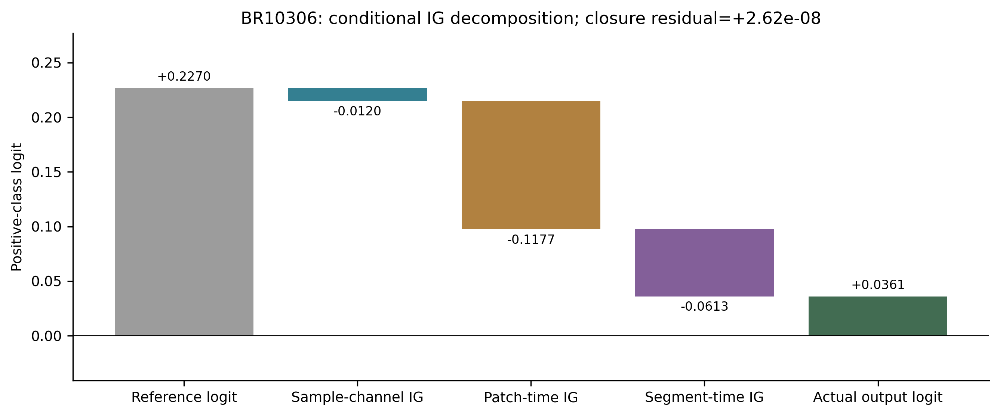

**case_TN_raw_signals** — Actual full source signals, no resampling; rasterized dense traces inside vector SVG. Invalid derivatives are gaps; pen state/boundaries retained. IG overlay includes sample-channel contributions only, time-metadata attribution remains separately stored. No clinical diagnosis inferred.

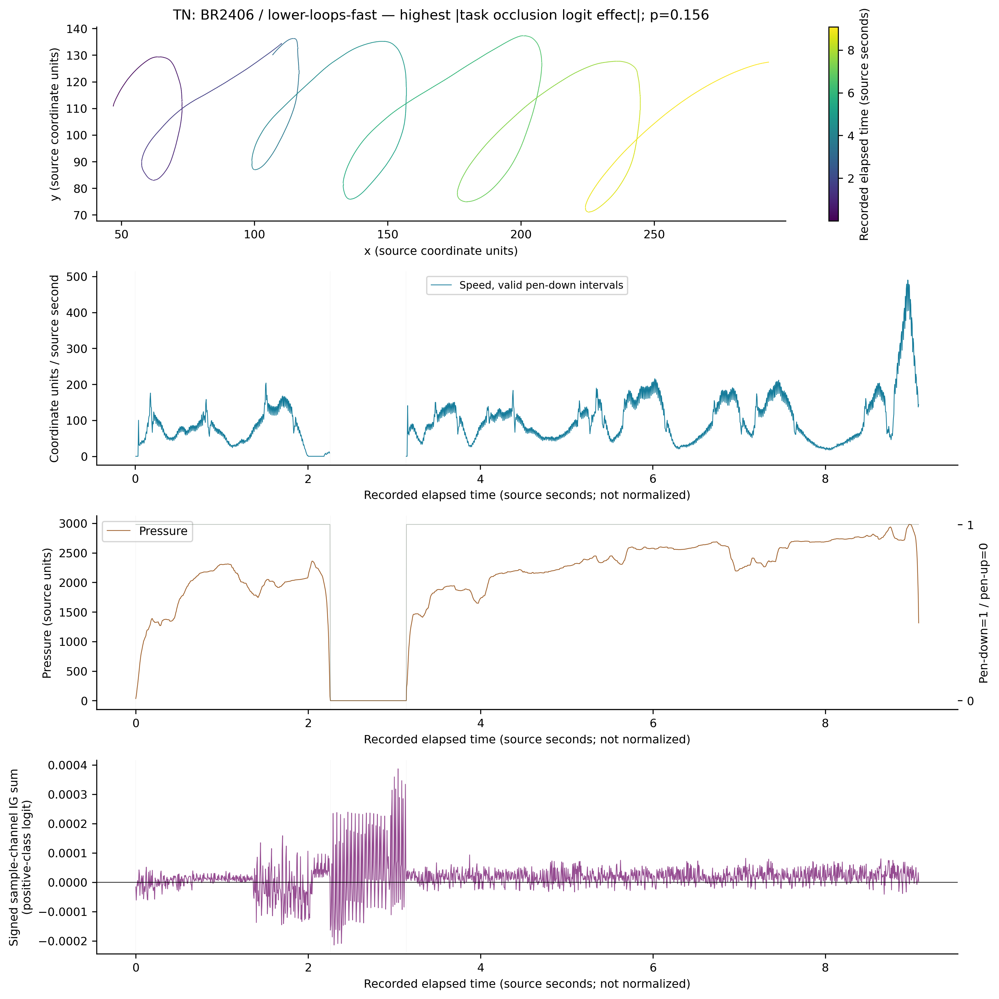

**case_TN_stroke_effects** — Joint whole-run occlusion mapped to original run indices; pen-down/pen-up distinguished; acceleration is a recorded-signal calculation, not a diagnosis.

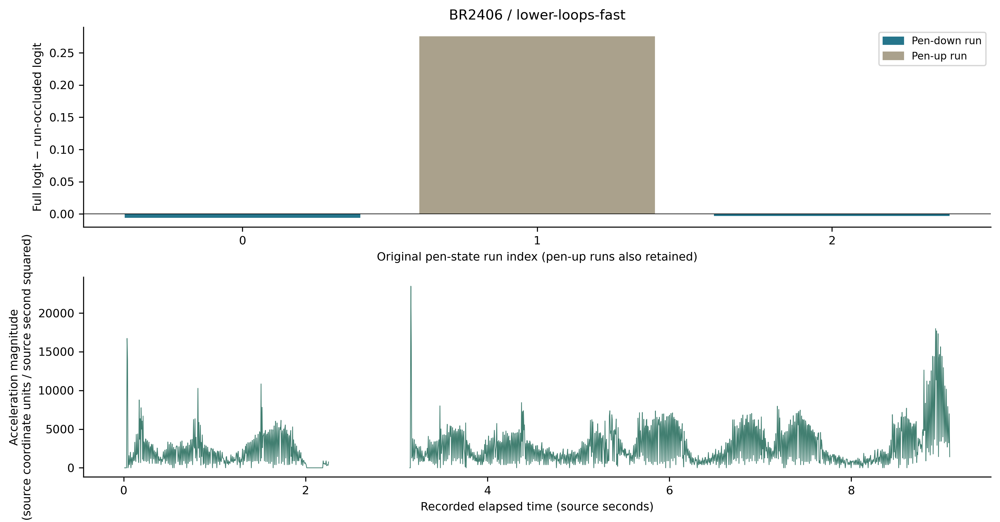

**case_TN_temporal_zoom** — Deterministic highest-absolute-IG window within the displayed task, independently matched to the descriptive table; not selected for visual appearance. No interpolation across invalid/gap intervals; red markers indicate clock boundaries. Narrow events are not diagnosed as tremor or disease.

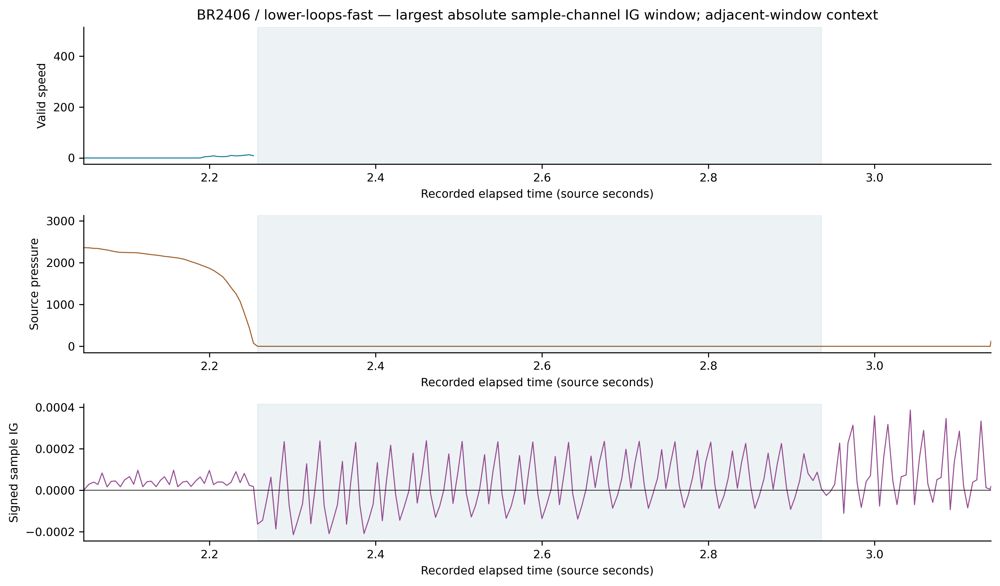

**case_TN_ig_components** — Reference plus signed sample/time-metadata IG approximates actual positive-class logit within validated tolerance. Structural task IDs, masks and segmentation held fixed; reference is mathematical, not a healthy recording.

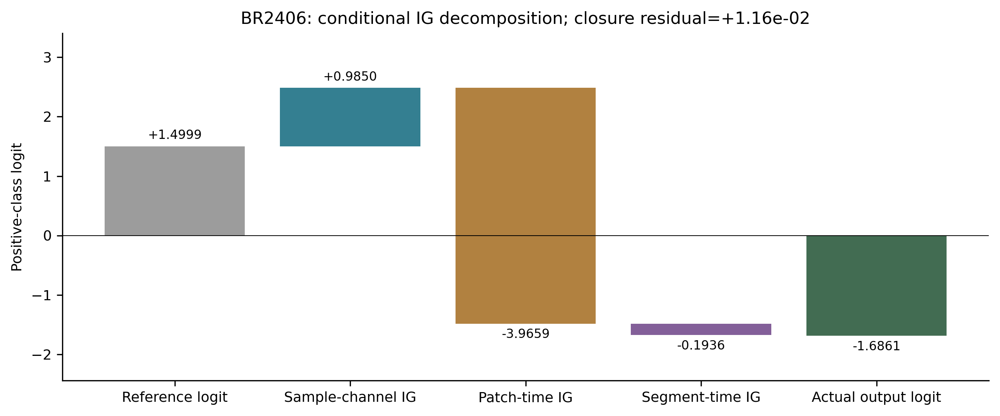

**case_FN_raw_signals** — Actual full source signals, no resampling; rasterized dense traces inside vector SVG. Invalid derivatives are gaps; pen state/boundaries retained. IG overlay includes sample-channel contributions only, time-metadata attribution remains separately stored. No clinical diagnosis inferred.

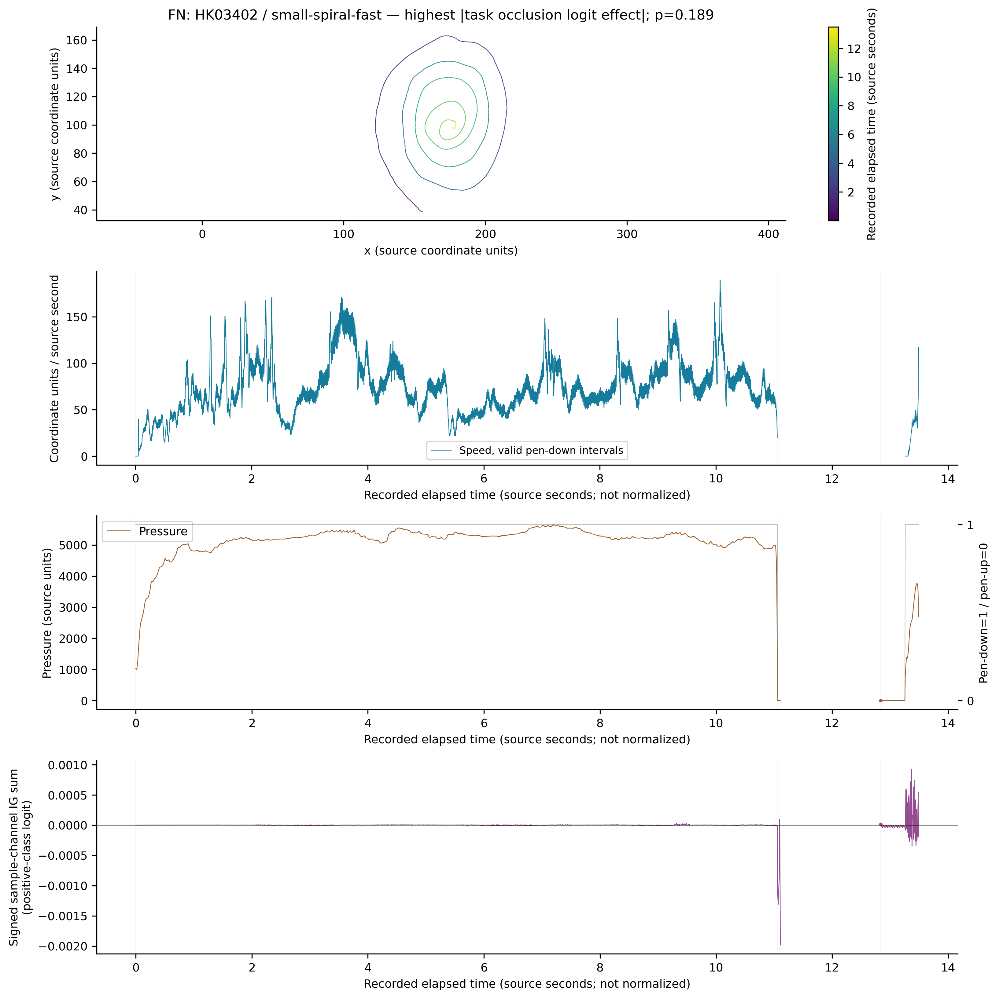

**case_FN_stroke_effects** — Joint whole-run occlusion mapped to original run indices; pen-down/pen-up distinguished; acceleration is a recorded-signal calculation, not a diagnosis.

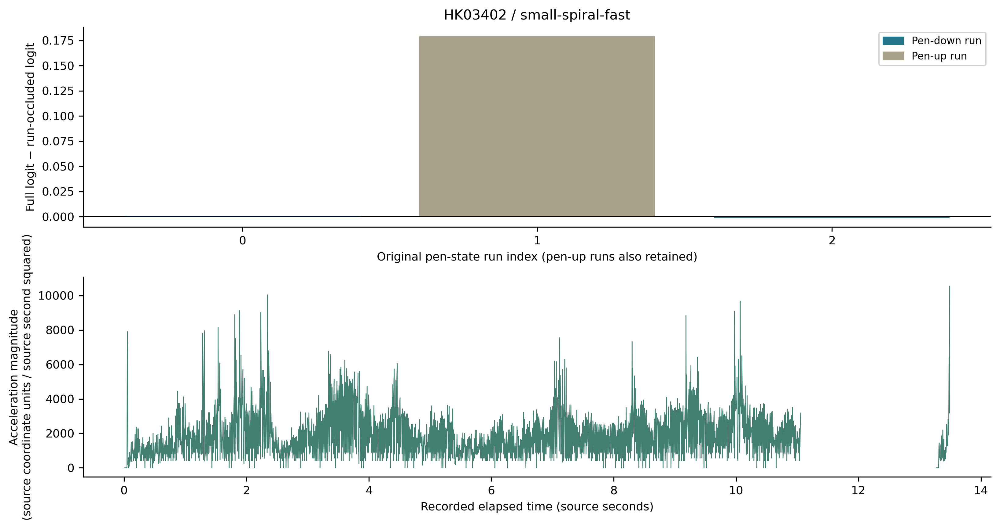

**case_FN_temporal_zoom** — Deterministic highest-absolute-IG window within the displayed task, independently matched to the descriptive table; not selected for visual appearance. No interpolation across invalid/gap intervals; red markers indicate clock boundaries. Narrow events are not diagnosed as tremor or disease.

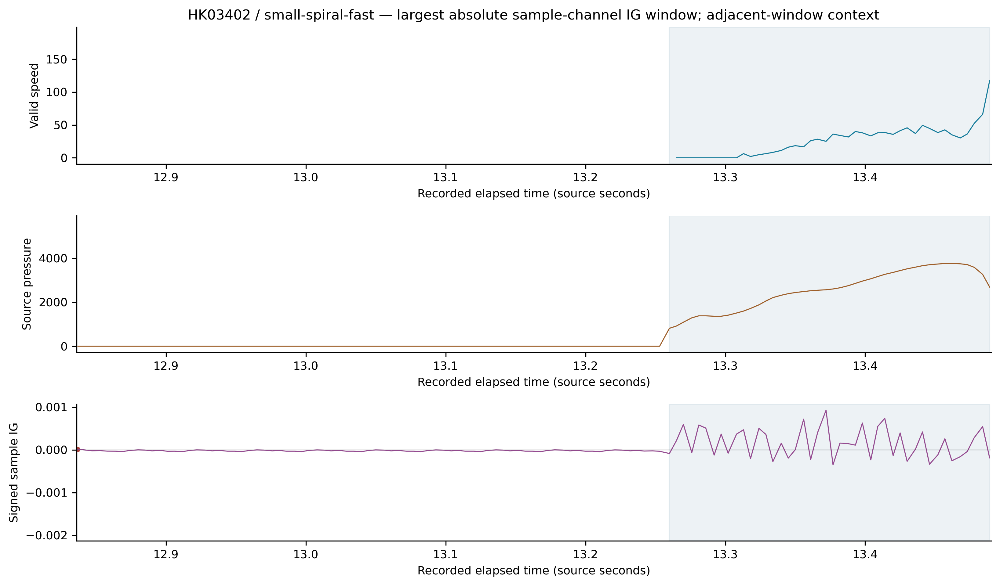

**case_FN_ig_components** — Reference plus signed sample/time-metadata IG approximates actual positive-class logit within validated tolerance. Structural task IDs, masks and segmentation held fixed; reference is mathematical, not a healthy recording.

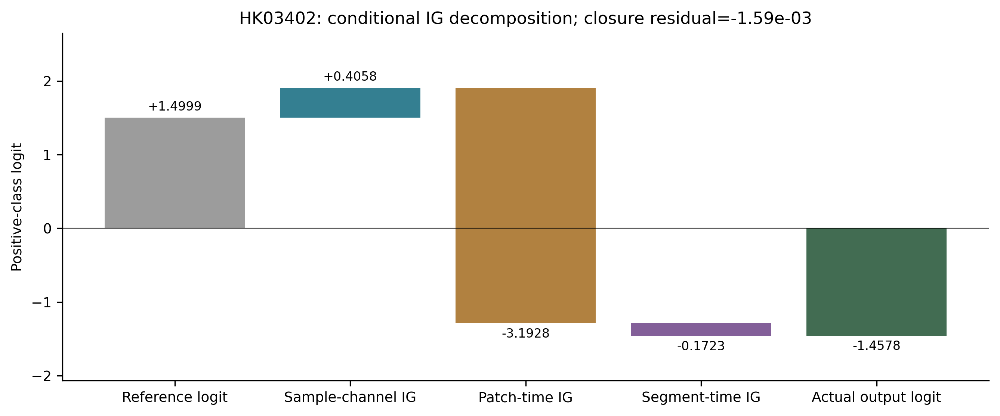

In [16]:
manifest=json.loads((OUT/'figures/manifest.json').read_text())
for row in manifest:
    display(Markdown('**'+row['name']+'** — '+row['caption']))
    display(Image(filename=str(OUT/'figures'/(row['name']+'.png')),width=1000))

## Giới hạn và trạng thái bàn giao

Cohort/folds đã được xem ở các nghiên cứu trước: nested implementation không xóa adaptive research bias. Không external validation, cross-language hoặc fusion. Đánh giá architecture chưa capacity-match hoàn toàn, context bị giới hạn theo chunks. Đọc đầy đủ negative results, sự khác nhau giữa ablations và sensor assumptions trong báo cáo.

In [17]:
display(Markdown('Trạng thái hoàn tất sau notebook/tests: [validation.json](../results/raw_temporal/validation.json).'))
display(Markdown('Báo cáo: [REPORT_VI.md](../results/raw_temporal/REPORT_VI.md) — Audit: [audit/REPORT_VI.md](../results/raw_temporal/audit/REPORT_VI.md).'))

Trạng thái hoàn tất sau notebook/tests: [validation.json](../results/raw_temporal/validation.json).

Báo cáo: [REPORT_VI.md](../results/raw_temporal/REPORT_VI.md) — Audit: [audit/REPORT_VI.md](../results/raw_temporal/audit/REPORT_VI.md).